In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root OR from app/L9 in GitHub Codespaces.
def data_file(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/{filename}. Open this notebook inside ProgrammingForDA.")

## Read and understand the columns

This is an observational dataset: each row represents a restaurant bill, not a person or a prediction.

In [9]:
df = pd.read_csv(data_file("restaurant_tips.csv"))
print(df.shape)
print(df.head())
print(df.dtypes)

(244, 7)
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
total_bill    float64
tip           float64
sex            object
smoker         object
day            object
time           object
size            int64
dtype: object


## Check quality before modelling

Inspect missing values and numerical summaries. A good model cannot compensate for misunderstood data.

In [10]:
print("Missing values by column:\n", df.isna().sum())
print("Numerical summary:\n", df.describe().round(2))
print("Dinner/lunch counts:\n", df["time"].value_counts())

Missing values by column:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
Numerical summary:
        total_bill     tip    size
count      244.00  244.00  244.00
mean        19.79    3.00    2.57
std          8.90    1.38    0.95
min          3.07    1.00    1.00
25%         13.35    2.00    2.00
50%         17.80    2.90    2.00
75%         24.13    3.56    3.00
max         50.81   10.00    6.00
Dinner/lunch counts:
 time
Dinner    176
Lunch      68
Name: count, dtype: int64


## Explore patterns visually

A scatter plot reveals the relationship between total bill and tip, but it does not prove causation.

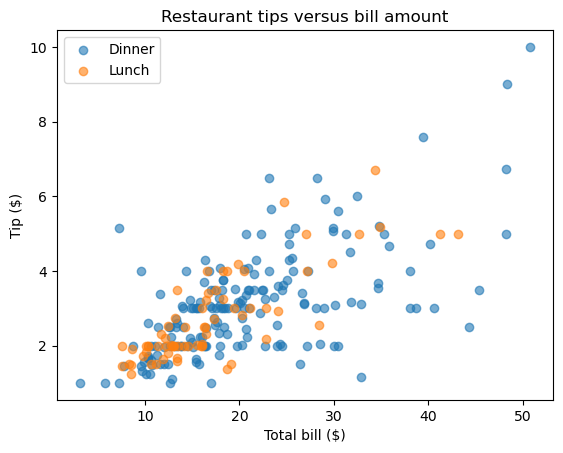

In [11]:
for name, group in df.groupby("time"):
    plt.scatter(group["total_bill"], group["tip"], label=name, alpha=0.6)
plt.xlabel("Total bill ($)")
plt.ylabel("Tip ($)")
plt.title("Restaurant tips versus bill amount")
plt.legend()
plt.show()

## Compare several numerical features

A scatter-matrix shows pairwise relationships and the distribution of each variable.

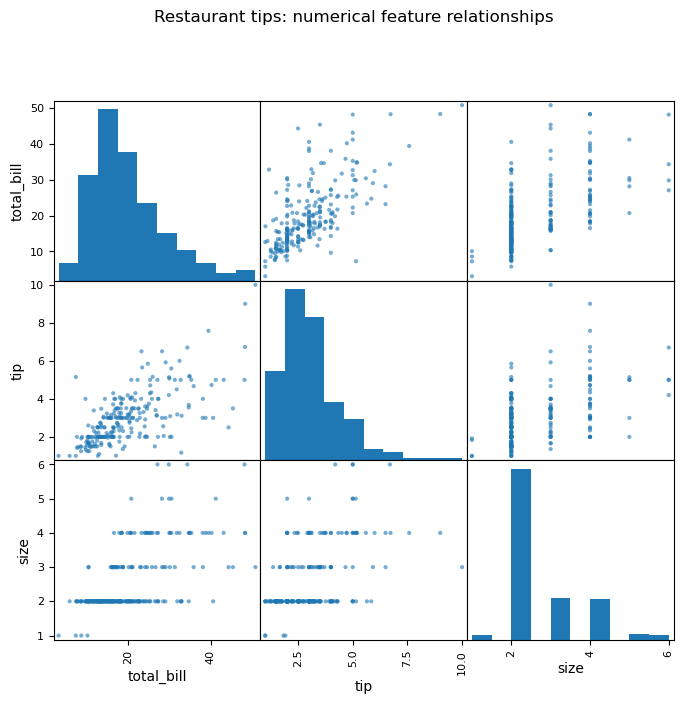

In [12]:
from pandas.plotting import scatter_matrix
scatter_matrix(df[["total_bill", "tip", "size"]], figsize=(8, 7), diagonal="hist", alpha=0.6)
plt.suptitle("Restaurant tips: numerical feature relationships", y=1.01)
plt.show()

## Choose features and a target

If we want to estimate a future tip, `tip` is the target (y), while bill amount and party size are possible features (X).

In [13]:
X = df[["total_bill", "size"]]
y = df["tip"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Median tip by meal time:\n", df.groupby("time")["tip"].median().round(2))

X shape: (244, 2)
y shape: (244,)
Median tip by meal time:
 time
Dinner    3.00
Lunch     2.25
Name: tip, dtype: float64


## Your turn — short challenge

Calculate `tip_percentage = 100 * tip / total_bill`, then compare the **median tip percentage by day**. Which day has the highest median? Does this prove customers on that day are more generous?

Try it yourself first. The instructor copy contains a worked answer.

In [14]:
# TODO: write your answer here.
# Hint: reuse the variables created above.